# Quadratic inference Pareto front (3D) in the scattered-voltage basis

Same as `quadraticInferencePareto.ipynb`, but with the bound formulated in the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$
(as in `VscatBound.ipynb`): global bound (real and reactive power conservation) → GCD refinement → continuation of the quadratic
inference problem with the original objective added as a constraint

$$\min_\delta \tilde J_\mathrm{inf}^{(k)}(\delta)\quad \text{s.t.}\quad (x-x_\mathrm{opt})^H L^\star (x-x_\mathrm{opt}) = \varepsilon,\qquad P(x) = P_\mathrm{target},$$

where $L^\star = A(\lambda^\star)$ is now the quadratic part of the Lagrangian in $V_\mathrm{sca}$, so the Lagrangian distance and the
trust region of the continuation are measured in the voltage. $P_\mathrm{target}$ is swept between the full-plate value and the GCD bound;
for each level the continuation starts at the point of minimal Lagrangian distance and $\varepsilon$ is swept upwards. Each step uses the
Hermitian Takagi upper model $H+P$ and is solved as a `DenseSharedProjQCQP` with two general constraints and no projector constraints.

In [1]:
import numpy as np
import scipy.sparse as sp
import time
from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
import copy
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
wavelength = c / frequency # wavelength in m
print(f"Wavelength: {wavelength} m")

ka = 1 # electrical size of the antenna
k = 2 * np.pi / wavelength # wavenumber
a = ka / k # antenna circumradius
print(f"Antenna circumradius: {a} m")

omega = 2 * np.pi * frequency # angular frequency

conductivity_reduction_factor = 1 # factor to reduce conductivity for testing purposes
copper_conductivity = conductivity_reduction_factor*5.96e7 # S/m
copper_permittivity = 1 + 1j * copper_conductivity / (omega * epsilon_0) # copper permittivity in dimensionless units
print(f"Copper permittivity: {copper_permittivity:.2e}")

Wavelength: 0.1223655664053944 m
Antenna circumradius: 0.019475084757658086 m
Copper permittivity: 1.00e+00+4.37e+08j


In [3]:
# Calculate surface impedance
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta)
print(f"Surface impedance: {Zs} Ω")

# Load matrices from text files
Lmat = np.loadtxt(r"Lmat_dipole.txt", delimiter=',') # lossy matrix

Ndes = Lmat.shape[0] # number of design variables
print("Number of design variables: ", Ndes)

Lchol = np.linalg.cholesky(Lmat).conj().T
LcholInv = np.linalg.inv(Lchol)

def Msym(M):
    return(0.5*(M.conj().T + M))

def Mchol(M):
    return(Msym(LcholInv.conj().T @ M @ LcholInv))

R0 = np.loadtxt(r"R0_dipole.txt", delimiter=',') # radiated power matrix
R0 = Mchol(R0)

X0 = np.loadtxt(r"X0_dipole.txt", delimiter=',') # reactive power matrix
X0 = Mchol(X0)

Vinc = np.loadtxt(r"V_dipole.txt", delimiter=',') # voltage excitation vector
Vinc = E0*Vinc
def Vchol(v):
    return(LcholInv.conj().T @ v)
Vinc = Vchol(Vinc)

Zmat = Zs * np.eye(Ndes) # material impedance matrix
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix

def evalObjI(Ivec):
    # radiated power in the current basis
    return(0.5*np.real(Ivec.conj().T @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc) # current distribution for full plate
Pfull = evalObjI(Ifull) # objective for full plate
print(f"Objective for full plate: {Pfull:.6e} W")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω
Number of design variables:  195
Objective for full plate: 1.010821e+01 W


## Objective and power conservation in $V_\mathrm{sca}$

With $I = -W V_\mathrm{sca}$, $W = Z_0^{-1}$, the radiated power is $-x^H A_0 x$ with $A_0 = -\tfrac12 W^H R_0 W$, and the power conservation
constraints take the shared projector form with $A_1 = 1 + Z_s^* W^H$, $A_2 = W$, $s_1 = -\tfrac12 V$ (derivation in `VscatBound.ipynb`).

In [4]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0)   # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0

def VtoI(Vsca):
    return(-W @ Vsca)

def evalObj(Vsca):
    return(-np.real(Vsca.conj().T @ Obj @ Vsca) + 2*np.real(Vsca.conj().T @ obj) + obj0)

Vfull = -Z0 @ Ifull # scattered voltage for full plate
print(f"Objective for full plate in Vsca: {evalObj(Vfull):.6e} W (I basis {Pfull:.6e} W)")

cond(Z0) = 1.750e+04
Objective for full plate in Vsca: 1.010821e+01 W (I basis 1.010821e+01 W)


In [5]:
A1 = np.eye(Ndes) + np.conj(Zs) * WH
A2 = W
s1 = -0.5 * Vinc

qList = [1, -1j]   # real and imaginary part (real and reactive power), p = q 1
Plist = [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qList]   # P' = diag(p^*)

def projRes(x, Pp):
    # Re(-x^H A1 P' A2 x + 2 x^H A2^H P'^H s1)
    return(np.real(-x.conj() @ A1 @ (Pp @ (A2 @ x)) + 2*x.conj() @ (A2.conj().T @ (Pp.conj().T @ s1))))

def directRes(Vsca, p):
    # Re[I^H diag(p) (V + Vsca - Zs I)] evaluated directly
    I = VtoI(Vsca)
    return(np.real(np.sum(p*np.conj(I)*(Vinc + Vsca - Zs*I))))

print("power conservation residuals at full plate:",
      [f"{projRes(Vfull, Pp):.2e} (direct {directRes(Vfull, q*np.ones(Ndes)):.2e})" for Pp, q in zip(Plist, qList)])

# check: shared projector form equals the direct constraint for a random projector at a random point
pRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
xRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
print(f"random p, random x: shared form {projRes(xRand, sp.diags(np.conj(pRand))):.6e}, direct {directRes(xRand, pRand):.6e}")

power conservation residuals at full plate: ['-3.73e-13 (direct -3.72e-13)', '2.64e-12 (direct 2.64e-12)']
random p, random x: shared form -3.175688e-02, direct -3.175688e-02


## Global bound

In [6]:
QCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=1)

lags_init = np.array([1.0, 0.0])   # lambda = 1 on the real power constraint
print(f"initial lags dual feasible: {QCQP.is_dual_feasible(lags_init)}")

opt_params = OptimizationHyperparameters(opttol=1e-6,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=10,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

t1 = time.time()
result = QCQP.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=opt_params)
print(f"bound: {result[0]:.6e} W, time: {time.time()-t1:.2f}s, Lagrange multipliers: {QCQP.current_lags}")

lags = QCQP.current_lags
totalA = QCQP._get_total_A(lags)
print(f"minimum eigenvalue of A: {np.min(np.linalg.eigvalsh(Msym(totalA))):.3e}")

Vstar = QCQP.current_xstar
Istar = VtoI(Vstar)
print(f"dual bound {QCQP.current_dual:.6e} W, P(x*) {evalObj(Vstar):.6e} W (I basis {evalObjI(Istar):.6e} W), full plate {Pfull:.6e} W")
print("constraint residuals at x*:", [f"{projRes(Vstar, Pp):.2e}" for Pp in Plist])

Precomputed 2 A matrices and Fs vectors.
initial lags dual feasible: True
bound: 1.012093e+01 W, time: 0.06s, Lagrange multipliers: [ 0.98806808 -0.03777126]
minimum eigenvalue of A: 1.813e-06
dual bound 1.012093e+01 W, P(x*) 1.012093e+01 W (I basis 1.012093e+01 W), full plate 1.010821e+01 W
constraint residuals at x*: ['4.99e-09', '6.68e-08']


## Local projector constraints by GCD

In [7]:
Ngcd = 40   # number of GCD iterations, each adds a max violation and a min eigenvalue projector

gQCQP = copy.deepcopy(QCQP)
gQCQP.verbose = 0
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1,   # no early termination
    opt_params=opt_params)

t1 = time.time()
gQCQP.run_gcd(gcd_params)
print(f"bound: {QCQP.current_dual:.6e} -> {gQCQP.current_dual:.6e} W (full plate {Pfull:.6e} W), "
      f"{gQCQP.n_proj_constr} projectors, {time.time()-t1:.2f}s")

At GCD iteration #1, best dual bound found is             10.120932760127525.
min eigenvalue: 1.812902e-06


At GCD iteration #2, best dual bound found is             10.113198452252506.
min eigenvalue: 1.421461e-06
At GCD iteration #3, best dual bound found is             10.113175883310445.
min eigenvalue: 1.420209e-06


At GCD iteration #4, best dual bound found is             10.112937260659097.
min eigenvalue: 1.408314e-06
At GCD iteration #5, best dual bound found is             10.111878772115862.
min eigenvalue: 1.353024e-06


At GCD iteration #6, best dual bound found is             10.111399204537923.
min eigenvalue: 1.326256e-06
At GCD iteration #7, best dual bound found is             10.111025492143757.
min eigenvalue: 1.304832e-06


At GCD iteration #8, best dual bound found is             10.110879425378696.
min eigenvalue: 1.296015e-06
At GCD iteration #9, best dual bound found is             10.110797311244651.
min eigenvalue: 1.290925e-06


...

At GCD iteration #37, best dual bound found is             10.108666728836834.
min eigenvalue: 1.130938e-06


At GCD iteration #38, best dual bound found is             10.10863941866543.
min eigenvalue: 1.128784e-06


At GCD iteration #39, best dual bound found is             10.108614783999316.
min eigenvalue: 1.126871e-06


At GCD iteration #40, best dual bound found is             10.108588195714942.
min eigenvalue: 1.124852e-06


At GCD iteration #41, best dual bound found is             10.108563075762232.
bound: 1.012093e+01 -> 1.010856e+01 W (full plate 1.010821e+01 W), 82 projectors, 12.85s


In [8]:
# finetune the GCD multipliers with BFGS and check PSD-ness of A
t1 = time.time()
gcd_final_result = gQCQP.solve_current_dual_problem(method='bfgs', init_lags=gQCQP.current_lags, opt_params=None)
print(f"bound: {gcd_final_result[0]:.6e} W, time: {time.time()-t1:.2f}s")

print(f"min eigenvalue of A: {np.min(np.linalg.eigvalsh(Msym(gQCQP._get_total_A(gQCQP.current_lags)))):.3e}")
Vstar = gQCQP.current_xstar
print(f"GCD primal objective: {evalObj(Vstar):.6e} W, GCD dual bound: {gQCQP.current_dual:.6e} W")

bound: 1.010856e+01 W, time: 0.34s
min eigenvalue of A: 1.123e-06
GCD primal objective: 1.010856e+01 W, GCD dual bound: 1.010856e+01 W


## Quadratic inference model in $V_\mathrm{sca}$

The inference error $J_\mathrm{inf} = \sum_i |a_i b_i^*|^2$ uses the vacuum residual $a = Z_s I$ and the material residual
$b = (Z_s + Z_0) I - V$. With $I = -W x$ both are affine in $x$,
$$a = M_a x,\quad M_a = -Z_s W, \qquad b = M_b x - V,\quad M_b = -(1 + Z_s W),$$
and the second order expansion $J_\mathrm{inf}(x+d) \approx J_0 + 2\operatorname{Re}(g^H d) + d^H H d + \operatorname{Re}(d^T K d)$ has
$$g = M_a^H (|b|^2 a) + M_b^H (|a|^2 b),$$
$$H = M_a^H \operatorname{diag}|b|^2 M_a + M_b^H \operatorname{diag}|a|^2 M_b + M_a^H \operatorname{diag}(q) M_b + M_b^H \operatorname{diag}(q^*) M_a,\quad q = a b^*,$$
$$K = 2 M_a^T \operatorname{diag}(a^* b^*) M_b .$$
For the current basis ($M_a = Z_s$, $M_b = Z_s + Z_0$) this reduces to the expansion of `quadraticInferencePareto.ipynb`.

In [9]:
from scipy.optimize import brentq

Vopt = gQCQP.current_xstar
Lstar = Msym(gQCQP._get_total_A(gQCQP.current_lags))   # quadratic part of the Lagrangian (Vsca basis)
lamMinL = np.min(np.linalg.eigvalsh(Lstar))
print(f"min eig L*: {lamMinL:.3e}")

Vzero = np.zeros(Ndes, dtype=complex)
Ma = -Zs*W                        # a = Zs I = Ma x
Mb = -(np.eye(Ndes) + Zs*W)       # b = (Zs + Z0) I - V = Mb x - V

def residuals(x):
    return Ma @ x, Mb @ x - Vinc          # vacuum residual a, material residual b

def Jinf(x):
    a, b = residuals(x)
    return np.sum(np.abs(a*b.conj())**2)

def inferredDensity(x):
    a, b = residuals(x)
    return a/(a - b)                        # = Zs I / (V + Vsca)

def taylor(x):
    """g, H, K of the second-order expansion of Jinf at x."""
    a, b = residuals(x)
    q = a*b.conj()
    Da, Db = np.abs(a)**2, np.abs(b)**2
    g = Ma.conj().T @ (Db*a) + Mb.conj().T @ (Da*b)
    H = (Ma.conj().T @ (Db[:, None]*Ma) + Mb.conj().T @ (Da[:, None]*Mb)
         + Mb.conj().T @ (q.conj()[:, None]*Ma) + Ma.conj().T @ (q[:, None]*Mb))
    K = 2*Ma.T @ (np.conj(a*b)[:, None]*Mb)
    return g, Msym(H), 0.5*(K + K.T)

def predicted(x, d):
    g, H, K = taylor(x)
    return Jinf(x) + 2*np.real(g.conj() @ d) + np.real(d.conj() @ H @ d) + np.real(d @ K @ d)

# sanity check of the expansion: error should scale as t^3
rng = np.random.default_rng(0)
dir_ = rng.standard_normal(Ndes) + 1j*rng.standard_normal(Ndes); dir_ *= np.linalg.norm(Vopt)/np.linalg.norm(dir_)
for t in [1e-2, 1e-3, 1e-4]:
    print(f"t={t:.0e}: |J - J~| / J = {abs(Jinf(Vopt + t*dir_) - predicted(Vopt, t*dir_))/Jinf(Vopt):.3e}")
# consistency with the current basis: J_inf(x) = J_inf of I = -W x
Itest = VtoI(Vopt)
print(f"J_inf in Vsca basis {Jinf(Vopt):.6e}, in I basis {np.sum(np.abs(Zs*Itest*np.conj(Ztot @ Itest - Vinc))**2):.6e}")

min eig L*: 1.123e-06
t=1e-02: |J - J~| / J = 9.241e-07
t=1e-03: |J - J~| / J = 9.255e-10
t=1e-04: |J - J~| / J = 9.259e-13
J_inf in Vsca basis 3.057319e-04, in I basis 3.057319e-04


## Inference QCQP with objective constraint

In [10]:
import scipy.linalg as sla

def realizedObj(dens):
    # radiated power of the structure with density dens: (Zs + diag(dens) Z0) I = diag(dens) V
    S = np.diag(dens.astype(complex))
    I = np.linalg.solve(Zs*np.eye(Ndes) + S @ Z0, S @ Vinc)
    return evalObjI(I)

def lagDist(I):
    e = I - Vopt
    return np.real(e.conj() @ Lstar @ e)

import os, warnings
INF_TOL = float(os.environ.get('INF_TOL', '1e-6'))   # dual tolerance of the inference QCQP
Pdual = gQCQP.current_dual

inf_opt = OptimizationHyperparameters(opttol=INF_TOL, gradConverge=True, min_inner_iter=5, max_restart=10,
                                      penalty_ratio=1e-2, penalty_reduction=0.1, break_iter_period=5, verbose=0)

def takagiBound(K):
    """P = (K^H K)^{1/2}, so that |d^T K d| <= d^H P d (Takagi bound)."""
    _, s, Vh = np.linalg.svd(K)
    return Msym(Vh.conj().T @ (s[:, None]*Vh))

def inferenceStep(Ik, eps, Ptarget, lags0=None):
    """min of the Hermitian upper model J0 + 2Re[g^H x] + x^H (H + P) x, d = x - xk,
    s.t.  (x-Vopt)^H L* (x-Vopt) = eps  and  P(x) = Ptarget,
    posed for y = x - Vopt as a DenseSharedProjQCQP with two general constraints and no projector constraints."""
    g, H, K = taylor(Ik)
    M = Msym(H + takagiBound(K))
    e = Ik - Vopt
    J0 = Jinf(Ik)
    sc = 1/J0                                          # scale the objective to O(1)
    # maximize -J~(y - e)
    A0 = sc*M
    s0 = -sc*(g - M @ e)
    c0 = -sc*(J0 - 2*np.real(g.conj() @ e) + np.real(e.conj() @ M @ e))
    # Lagrangian distance:  -y^H L* y + eps = 0
    B1, s1g, c1 = Lstar/eps, Vzero, 1.0
    # original objective:  -(y+Vopt)^H Obj (y+Vopt) + 2Re[(y+Vopt)^H obj] + obj0 - Ptarget = 0
    B2 = Msym(Obj)/Ptarget
    s2g = (obj - Obj @ Vopt)/Ptarget
    c2 = (evalObj(Vopt) - Ptarget)/Ptarget
    Q = DenseSharedProjQCQP(A0, s0, c0, np.eye(Ndes, dtype=complex), Vzero,
                            [], Pstruct=sp.eye(Ndes),   # no projector constraints
                            B_j=[B1, B2], s_2j=[s1g, s2g], c_2j=[c1, c2], verbose=0)
    if lags0 is None:   # make A0 + mu L*/eps positive definite
        lmin = sla.eigh(A0, B1, eigvals_only=True, subset_by_index=[0, 0])[0]
        lags0 = np.array([max(-lmin, 0)*1.5 + 1.0, 0.0])
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            Q.solve_current_dual_problem(method='newton', init_lags=lags0, opt_params=inf_opt)
    except (ValueError, np.linalg.LinAlgError):
        return Ik, np.inf, None, np.inf               # failed solve -> rejected step
    I = Vopt + Q.current_xstar
    res = max(abs(lagDist(I) - eps)/eps, abs(evalObj(I) - Ptarget)/Ptarget)
    return I, predicted(Ik, I - Ik), Q.current_lags, res

def minEpsPoint(Ptarget):
    """Feasible starting point of the P level set closest to Vopt:
    min (x-Vopt)^H L* (x-Vopt)  s.t.  P(x) = Ptarget,
    a single-constraint QCQP (S-lemma, strong duality) as a DenseSharedProjQCQP."""
    B2 = Msym(Obj)/Ptarget
    s2g = (obj - Obj @ Vopt)/Ptarget
    c2 = (evalObj(Vopt) - Ptarget)/Ptarget
    Q = DenseSharedProjQCQP(Lstar, Vzero, 0.0, np.eye(Ndes, dtype=complex), Vzero,
                            [], Pstruct=sp.eye(Ndes),   # no projector constraints
                            B_j=[B2], s_2j=[s2g], c_2j=[c2], verbose=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        Q.solve_current_dual_problem(method='newton', init_lags=np.zeros(1), opt_params=inf_opt)
    I = Vopt + Q.current_xstar
    return I, lagDist(I), abs(evalObj(I) - Ptarget)/Ptarget


## 3D Pareto sweep

dual bound 1.010856e+01 W, P(Vopt) 1.010856e+01 W, full plate 1.010821e+01 W
L*-distance of the full plate: 3.496e-04, J_inf(Vopt) = 3.057e-04
sweep: coarse, 3 objective levels, eps growth 3.0, max 20 steps per level


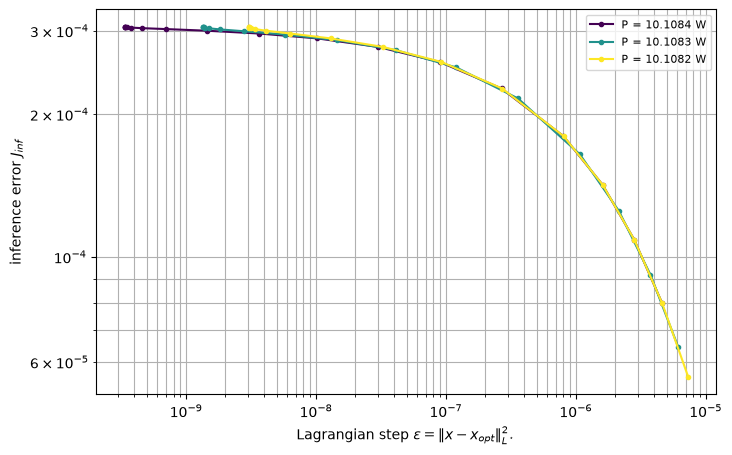

P = 10.10845 W: eps_min 3.355e-10, J_inf 3.057e-04, P residual 4.7e-14


  [  0] eps 3.358e-10 (d 3.35e-13): J_inf 3.056e-04, pred 3.056e-04 (err 0.0e+00), cstr res 5.5e-08, |dx|/|x| 4.7e-05, P(I) 1.01084e+01 W, lags [ 1.870e-01 -3.242e+04], 0.10s -> accepted


  step   1: eps 3.358e-10, J_inf 3.056e-04 (pred 3.056e-04), clipped design 1.9591e-07 W, binary design 6.8870e-12 W | 0 rejected, 0.11s


  [  1] eps 3.368e-10 (d 1.01e-12): J_inf 3.056e-04, pred 3.056e-04 (err 1.8e-16), cstr res 2.7e-08, |dx|/|x| 1.4e-07, P(I) 1.01084e+01 W, lags [ 1.871e-01 -3.238e+04], 0.04s -> accepted


  step   2: eps 3.368e-10, J_inf 3.056e-04 (pred 3.056e-04), clipped design 1.9591e-07 W, binary design 6.8870e-12 W | 0 rejected, 0.11s


...

  [ 18] eps 1.003e-05 (d 5.42e-06): J_inf 4.209e-05, pred 4.209e-05 (err 1.6e-06), cstr res 1.7e-07, |dx|/|x| 8.5e-02, P(I) 1.01082e+01 W, lags [ 0.401 -5.486], 0.05s -> rejected


  [ 19] eps 7.324e-06 (d 2.71e-06): J_inf 5.580e-05, pred 5.580e-05 (err 1.2e-07), cstr res 1.6e-07, |dx|/|x| 4.8e-02, P(I) 1.01082e+01 W, lags [  0.538 -10.886], 0.05s -> accepted


  step  16: eps 7.324e-06, J_inf 5.580e-05 (pred 5.580e-05), clipped design 4.5213e-07 W, binary design 6.8870e-12 W | 1 rejected, 0.15s


  level done: 16 accepted, 4 rejected, 2.2s


P = 10.10821 W: 17 points, eps_end 7.324e-06, J_inf 5.580e-05, binary 6.8870e-12 W
time 6.7s


In [11]:
epsFull = lagDist(Vfull)
print(f"dual bound {Pdual:.6e} W, P(Vopt) {evalObj(Vopt):.6e} W, full plate {Pfull:.6e} W")
print(f"L*-distance of the full plate: {epsFull:.3e}, J_inf(Vopt) = {Jinf(Vopt):.3e}")

import os
# sampling presets, selected by the environment variable SWEEP (coarse | fine)
SWEEP = os.environ.get('SWEEP', 'coarse')
nP, epsGrow, maxSteps = {'coarse': (3, 3.0, 20), 'fine': (20, 1.25, 400)}[SWEEP]
print(f"sweep: {SWEEP}, {nP} objective levels, eps growth {epsGrow}, max {maxSteps} steps per level")
Ptargets = np.linspace(Pdual, Pfull, nP + 1)[1:]       # from the bound downwards; P = Pdual only admits eps -> 0
epsMax = 1.2*epsFull
stepTol, predTol = 0.05, 0.1
Jtol = 1e-8*Jinf(Vopt)     # stopping threshold on the inference error

from IPython.display import display

# live figure: inference error vs Lagrangian step, one colour per objective level
liveFig, liveAx = plt.subplots(figsize=(8, 5))
liveAx.set_xscale('log'); liveAx.set_yscale('log')
liveAx.set_xlabel(r'Lagrangian step $\varepsilon = \|x-x_{opt}\|^2_{L^\star}$')
liveAx.set_ylabel(r'inference error $J_{inf}$')
liveAx.grid(True, which='both')
liveColors = plt.cm.viridis(np.linspace(0, 1, nP))
liveHandle = display(liveFig, display_id=True)
plt.close(liveFig)

def liveUpdate(line, pts):
    line.set_data([p[0] for p in pts], [p[1] for p in pts])
    liveAx.relim(); liveAx.autoscale_view()
    if liveHandle is not None:      # None outside Jupyter (batch runs)
        liveHandle.update(liveFig)

def sweepEps(Ptarget, color=None):
    # start on the P level set at the point of minimal Lagrangian distance; it is the
    # expansion point of the first Taylor model and eps_min is the smallest feasible eps
    Ik, epsk, res0 = minEpsPoint(Ptarget)
    d = np.real(inferredDensity(Ik))
    pts = [(epsk, Jinf(Ik), realizedObj(np.clip(d, 0, 1)), realizedObj((d > 0.5).astype(float)), Ik)]
    print(f"P = {Ptarget:.5f} W: eps_min {epsk:.3e}, J_inf {pts[0][1]:.3e}, P residual {res0:.1e}", flush=True)
    line, = liveAx.plot([], [], 'o-', ms=3, color=color, label=f'P = {Ptarget:.4f} W')
    liveAx.legend(fontsize=8); liveUpdate(line, pts)
    lags, dEps = None, 1e-3*epsk
    nRej, nRejTot, tStep, tLevel = 0, 0, time.time(), time.time()
    for it in range(maxSteps):
        if epsk >= epsMax or dEps < 1e-12*epsMax or pts[-1][1] < Jtol: break
        epsTry = min(epsk + dEps, epsMax)
        # the eps constraint is scaled as L*/eps, so the warm-start multiplier scales with eps
        lagsTry = None if lags is None else lags*np.array([epsTry/epsk, 1.0])
        tTry = time.time()
        I, Jpr, lagsNew, res = inferenceStep(Ik, epsTry, Ptarget, lagsTry)
        Jex = Jinf(I)
        relStep = np.linalg.norm(I - Ik)/np.linalg.norm(Ik)
        predErr = abs(Jex - Jpr)/abs(Jex)
        ok = res < 1e-4 and relStep < stepTol and predErr <= predTol
        lagStr = "None" if lagsNew is None else np.array2string(np.asarray(lagsNew), precision=3)
        print(f"  [{it:3d}] eps {epsTry:.3e} (d {dEps:.2e}): J_inf {Jex:.3e}, pred {Jpr:.3e} (err {predErr:.1e}), "
              f"cstr res {res:.1e}, |dx|/|x| {relStep:.1e}, P(I) {evalObj(I):.5e} W, lags {lagStr}, "
              f"{time.time()-tTry:.2f}s -> {'accepted' if ok else 'rejected'}", flush=True)
        if ok:
            Ik, epsk, lags = I, epsTry, lagsNew
            d = np.real(inferredDensity(I))
            pts.append((epsk, Jex, realizedObj(np.clip(d, 0, 1)), realizedObj((d > 0.5).astype(float)), I))
            print(f"  step {len(pts)-1:3d}: eps {epsk:.3e}, J_inf {Jex:.3e} (pred {Jpr:.3e}), "
                  f"clipped design {pts[-1][2]:.4e} W, binary design {pts[-1][3]:.4e} W | "
                  f"{nRej} rejected, {time.time()-tStep:.2f}s", flush=True)
            nRej, tStep = 0, time.time()
            liveUpdate(line, pts)
            dEps *= epsGrow
        else:
            dEps *= 0.5; lags = None
            nRej += 1; nRejTot += 1
    print(f"  level done: {len(pts)-1} accepted, {nRejTot} rejected, {time.time()-tLevel:.1f}s", flush=True)
    return pts

t1 = time.time()
front = {}
for i, P in enumerate(Ptargets):
    front[P] = sweepEps(P, liveColors[i])
    e = front[P][-1] if front[P] else None
    print(f"P = {P:.5f} W: {len(front[P])} points" + (f", eps_end {e[0]:.3e}, J_inf {e[1]:.3e}, binary {e[3]:.4e} W" if e else ""))
    if e and e[1] < Jtol:
        print(f"inference error below {Jtol:.1e}: realizable current found, stopping the sweeps")
        break
print(f"time {time.time()-t1:.1f}s")

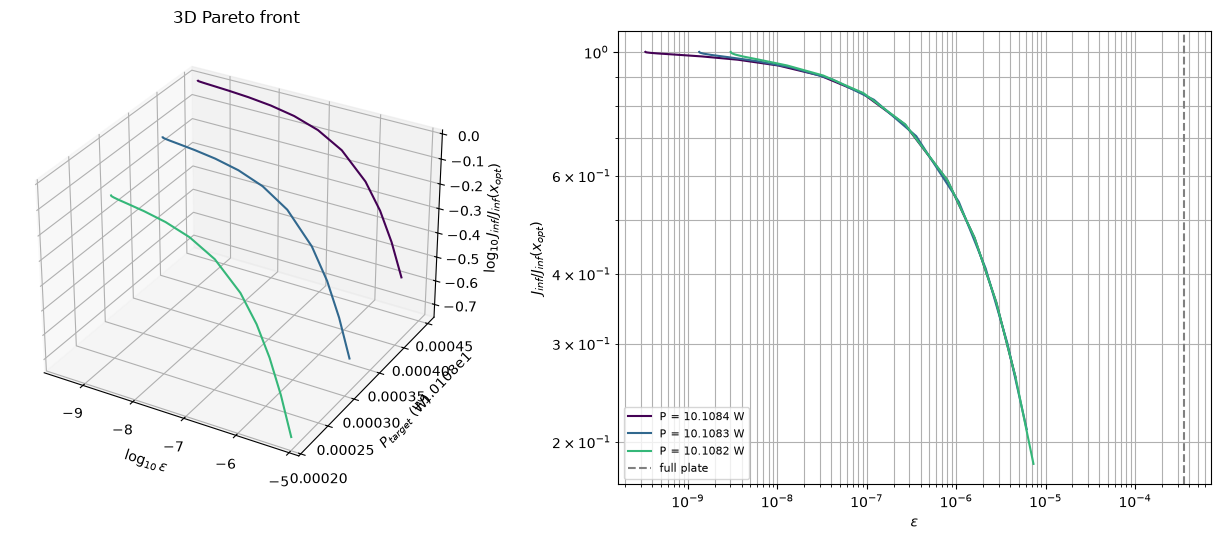

In [12]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
cmap = plt.cm.viridis
for i, (P, pts) in enumerate(front.items()):
    if not pts: continue
    e = np.array([p[0] for p in pts]); J = np.array([p[1] for p in pts])
    ax.plot(np.log10(e), P*np.ones_like(e), np.log10(J/Jinf(Vopt)), '-', color=cmap(i/len(front)))
ax.set_xlabel(r'$\log_{10}\varepsilon$'); ax.set_ylabel(r'$P_{target}$ (W)'); ax.set_zlabel(r'$\log_{10} J_{inf}/J_{inf}(x_{opt})$')
ax.set_title('3D Pareto front')
ax2 = fig.add_subplot(1, 2, 2)
for i, (P, pts) in enumerate(front.items()):
    if not pts: continue
    e = np.array([p[0] for p in pts]); J = np.array([p[1] for p in pts])
    ax2.loglog(e, J/Jinf(Vopt), '-', color=cmap(i/len(front)), label=f'P = {P:.4f} W')
ax2.axvline(epsFull, ls='--', c='gray', label='full plate')
ax2.set_xlabel(r'$\varepsilon$'); ax2.set_ylabel(r'$J_{inf}/J_{inf}(x_{opt})$'); ax2.grid(True, which='both'); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

best binary design: 6.887009e-12 W at P_target 10.10845 W, eps 3.005e-08 (full plate 1.010821e+01 W)


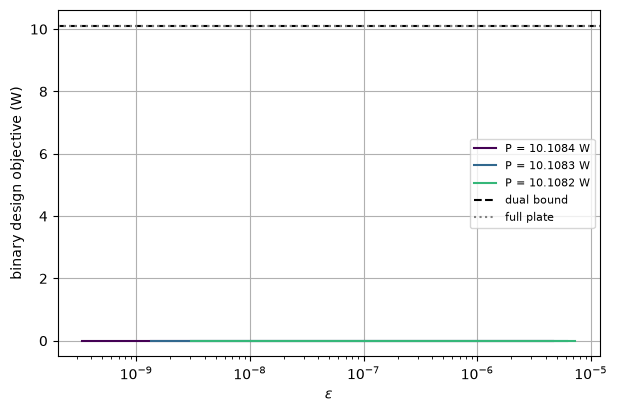

In [13]:
# realized objective of the binary (> 0.5) inferred designs along the front
best = max(((p[3], P, p[0]) for P, pts in front.items() for p in pts), default=(np.nan, np.nan, np.nan))
print(f"best binary design: {best[0]:.6e} W at P_target {best[1]:.5f} W, eps {best[2]:.3e} (full plate {Pfull:.6e} W)")
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (P, pts) in enumerate(front.items()):
    if not pts: continue
    ax.semilogx([p[0] for p in pts], [p[3] for p in pts], '-', color=cmap(i/len(front)), label=f'P = {P:.4f} W')
ax.axhline(Pdual, ls='--', c='k', label='dual bound'); ax.axhline(Pfull, ls=':', c='gray', label='full plate')
ax.set_xlabel(r'$\varepsilon$'); ax.set_ylabel('binary design objective (W)'); ax.grid(True); ax.legend(fontsize=8)
plt.show()

In [14]:
# save the front: rows (P_target, eps, J_inf, P_clipped, P_binary)
rows = [(P, p[0], p[1], p[2], p[3]) for P, pts in front.items() for p in pts]
np.savetxt(f'results/quadratic_inference_voltage_front_{SWEEP}.txt', np.array(rows), delimiter=',',
           header='P_target,eps,J_inf,P_clipped,P_binary')